Author: Aparajita Nath

Explore and prepare the credit data (quality checks, class balance, readable labels)

Data: [South German Credit (update)](https://archive.ics.uci.edu/dataset/573/south+german+credit), UCI Machine Learning Repository, [DOI 10.24432/C5QG88](https://doi.org/10.24432/C5QG88), CC BY 4.0. 1,000 historical consumer credits (1973-1975), 20 predictors and a good/bad outcome. Bad credits are over-sampled, so the bad share is not a real default rate.

Run the notebooks in order: A, B, C1, C2, C3, D, E.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import helpers as h

pd.set_option("display.max_columns", 30)

ModuleNotFoundError: No module named 'sklearn'

## 1. Explore the data

### 1.1 Load the data and rename the columns

The raw file uses German column names. They are renamed to the English names in the UCI code table.

In [ ]:
df = h.load_raw()
print(df.shape)
df.head()

(1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,4,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,2,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,4,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,2,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,4,2,38,1,2,2,2,2,1,1,1


### 1.2 Quality checks

In [ ]:
print(f"Records: {len(df):,}; columns: {df.shape[1]}")
print(f"Missing cells: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
print(f"Non-positive duration/amount/age: {int((df[h.CONTINUOUS] <= 0).sum().sum())}")
print()
pd.DataFrame({"distinct_values": df.nunique(), "min": df.min(), "max": df.max()})

Records: 1,000; columns: 21
Missing cells: 0
Duplicate rows: 0
Non-positive duration/amount/age: 0



,distinct_values,min,max
status,4,1,4
duration,33,4,72
credit_history,5,0,4
purpose,10,0,10
amount,923,250,18424
savings,5,1,5
employment_duration,5,1,5
installment_rate,4,1,4
personal_status_sex,4,1,4
other_debtors,3,1,3


### 1.3 Class balance

The source codes the outcome as 1 = good and 0 = bad. It is recoded here to `bad_credit` (1 = bad), so that the model output is the probability of a bad credit (PD).

         cases  share
outcome              
good       700    0.7
bad        300    0.3


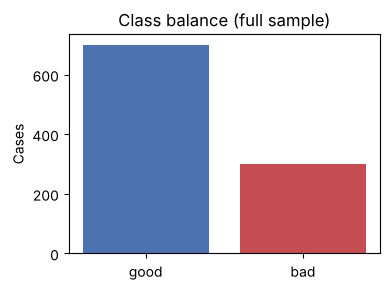

In [ ]:
df["bad_credit"] = (df["credit_risk"] == 0).astype(int)
df = df.drop(columns="credit_risk")

balance = df["bad_credit"].map({0: "good", 1: "bad"}).value_counts().rename_axis("outcome").to_frame("cases")
balance["share"] = (balance["cases"] / len(df)).round(3)
print(balance.to_string())

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(balance.index, balance["cases"], color=["#4c72b0", "#c44e52"])
ax.set(ylabel="Cases", title="Class balance (full sample)")
fig.tight_layout()
fig.savefig(h.FIGURES / "class_balance.png", dpi=160)
plt.show()

The sample has 30% bad credits because the source over-sampled them. The average predicted PD should therefore be compared with this sample, not with a bank portfolio.

### 1.4 Replace the codes by readable labels

The 17 categorical predictors are stored as small integer codes. They are decoded with the UCI code table, so that plots and model outputs are readable. `duration` (months), `amount` and `age` stay numeric.

In [ ]:
for col, mapping in h.LABELS.items():
    unknown = set(df[col].unique()) - set(mapping)
    assert not unknown, f"{col}: codes without a label: {unknown}"
    df[col] = df[col].map(mapping)
df.head()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,bad_credit
0,no checking account,18,all credits at this bank paid back duly,car (used),1049,unknown/no savings,< 1 yr,< 20,female: non-single or male: single,none,>= 7 yrs,car or other,21,none,for free,1 credit,skilled employee/official,0 to 2,no,no,0
1,no checking account,9,all credits at this bank paid back duly,others,2799,unknown/no savings,1 to 4 yrs,25 to 35,male: married/widowed,none,1 to 4 yrs,unknown/no property,36,none,for free,2-3 credits,skilled employee/official,3 or more,no,no,0
2,< 0 DM,12,no credits taken or all paid back duly,retraining,841,< 100 DM,4 to 7 yrs,25 to 35,female: non-single or male: single,none,>= 7 yrs,unknown/no property,23,none,for free,1 credit,unskilled resident,0 to 2,no,no,0
3,no checking account,12,all credits at this bank paid back duly,others,2122,unknown/no savings,1 to 4 yrs,20 to 25,male: married/widowed,none,1 to 4 yrs,unknown/no property,39,none,for free,2-3 credits,unskilled resident,3 or more,no,yes,0
4,no checking account,12,all credits at this bank paid back duly,others,2171,unknown/no savings,1 to 4 yrs,< 20,male: married/widowed,none,>= 7 yrs,car or other,38,bank,rent,2-3 credits,unskilled resident,0 to 2,no,yes,0


### 1.5 Look at the numeric variables

,duration,amount,age
count,1000.0,1000.0,1000.0
mean,20.9,3271.2,35.5
std,12.1,2822.8,11.4
min,4.0,250.0,19.0
25%,12.0,1365.5,27.0
50%,18.0,2319.5,33.0
75%,24.0,3972.2,42.0
max,72.0,18424.0,75.0


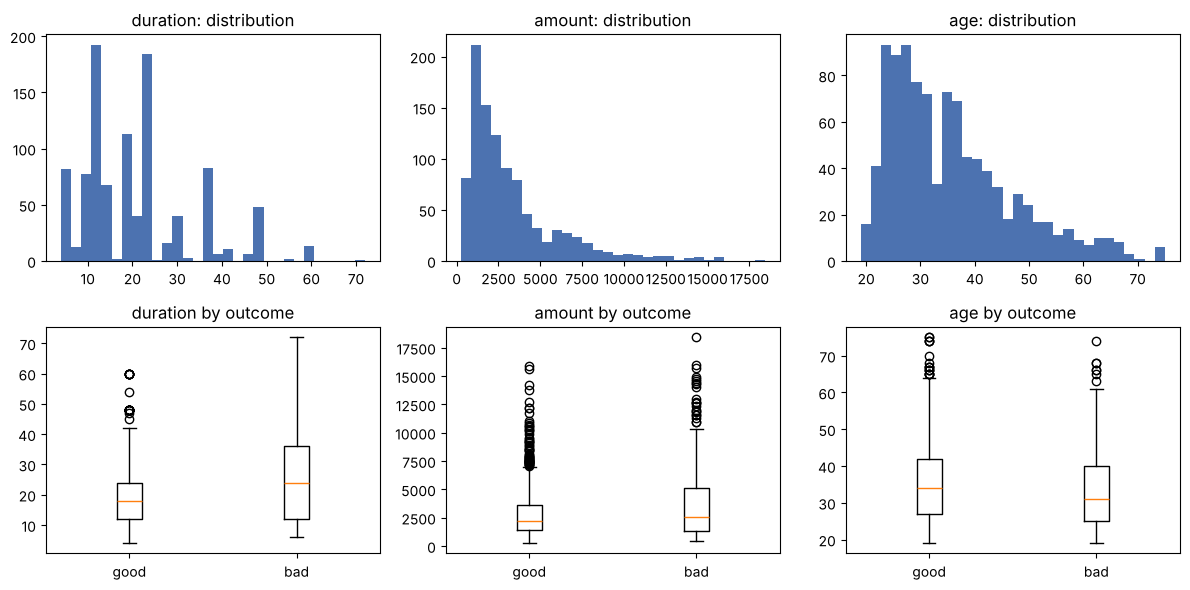

In [ ]:
display(df[h.CONTINUOUS].describe().round(1))

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, col in enumerate(h.CONTINUOUS):
    axes[0, j].hist(df[col], bins=30, color="#4c72b0")
    axes[0, j].set_title(f"{col}: distribution")
    data = [df.loc[df["bad_credit"] == 0, col], df.loc[df["bad_credit"] == 1, col]]
    axes[1, j].boxplot(data, tick_labels=["good", "bad"])
    axes[1, j].set_title(f"{col} by outcome")
fig.tight_layout()
fig.savefig(h.FIGURES / "numeric_variables.png", dpi=160)
plt.show()

`amount` is right-skewed with a few large loans, and long durations are rare. Neither looks like a data error (all values are positive and plausible), so no records are removed.

### 1.6 Bad rate by category (four variables)

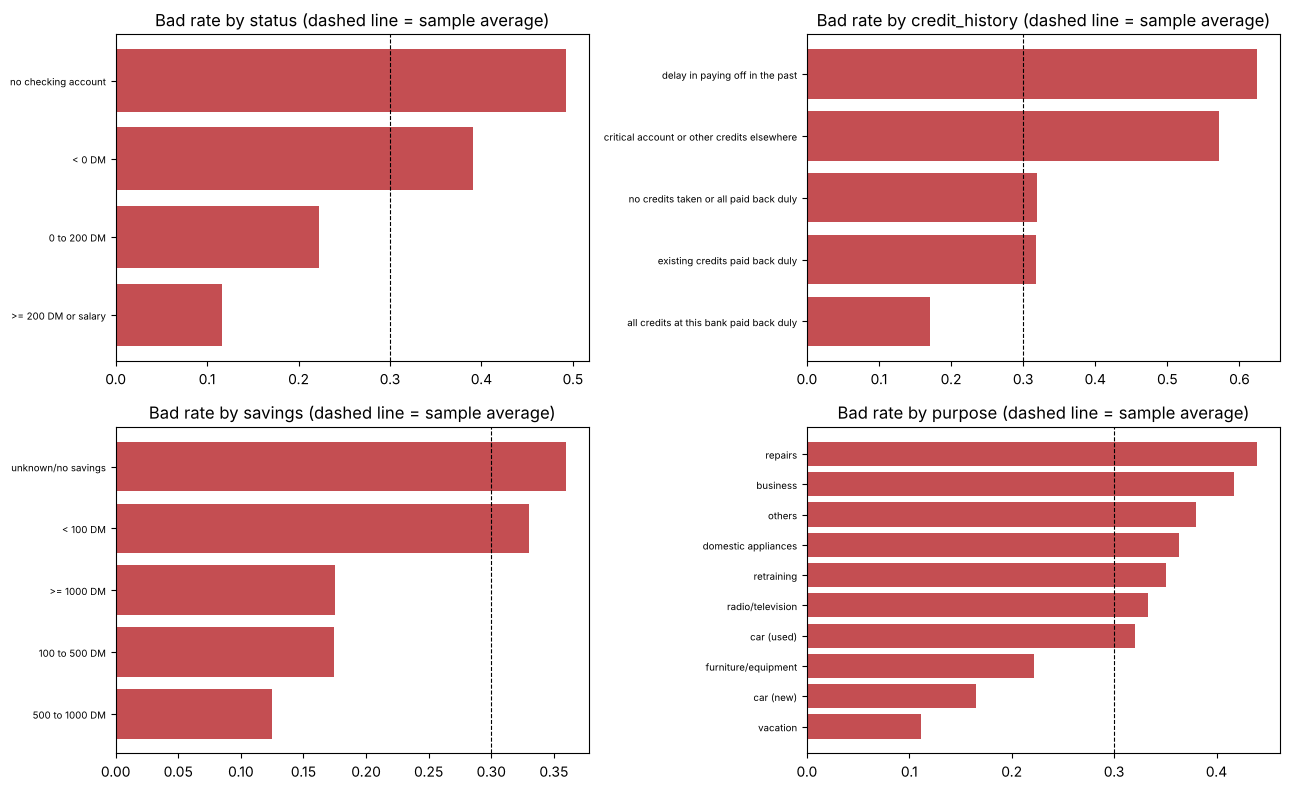

In [ ]:
show = ["status", "credit_history", "savings", "purpose"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), show):
    rate = df.groupby(col)["bad_credit"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(rate.index, rate["mean"], color="#c44e52")
    ax.axvline(df["bad_credit"].mean(), color="k", ls="--", lw=0.8)
    ax.set_title(f"Bad rate by {col} (dashed line = sample average)")
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
fig.savefig(h.FIGURES / "bad_rate_by_category.png", dpi=160)
plt.show()

### 1.7 Write the cleaned data out for the next step (B)

In [ ]:
df.to_csv(h.PROCESSED / "credit_clean.csv", index=False)
print("Saved", h.PROCESSED / "credit_clean.csv", df.shape)

Saved /tmp/claude-0/-home-claude/c4ad0277-ca65-5b57-96d4-708a1313c10d/scratchpad/build2/credit-risk-model-monitoring/data/processed/credit_clean.csv (1000, 21)
